In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt, colors as mplcolors, patches, ticker, cm

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# file_ids = [0]
plot_id = 0

In [4]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_datas(path, file_ids)
timestamps = [read_utils.get_timestamps(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

# clear nan values
for i in range(len(file_ids)):
	mask = markers[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	markers[i] = markers[i][mask]
	states[i] = states[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]
traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
#markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [5]:
plot_idx = file_ids.index(plot_id)

# raw

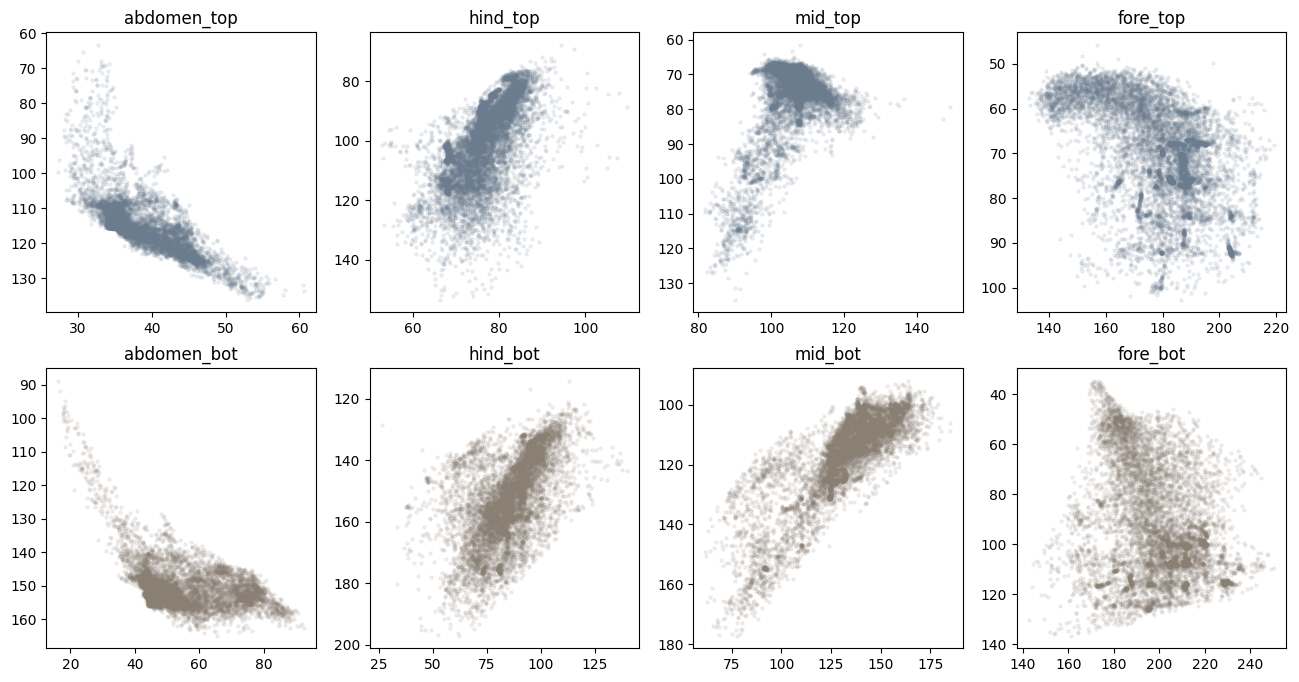

In [6]:
plot_utils.plot_markers(markers[plot_idx], join_topbot=False)

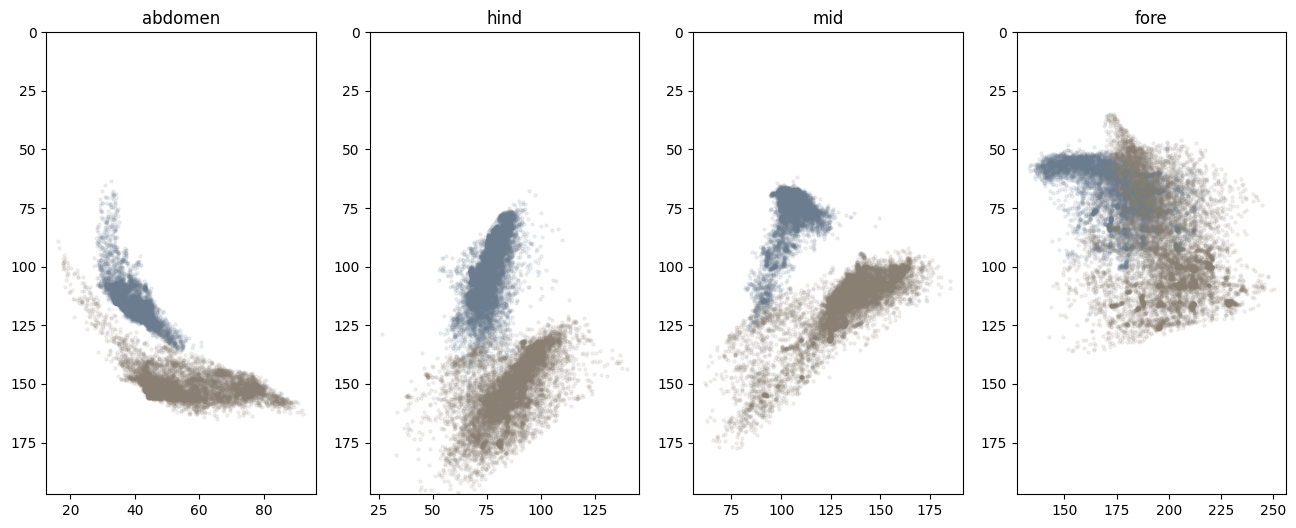

In [7]:
importlib.reload(plot_utils)
plot_utils.plot_markers(markers[plot_idx], join_topbot=True)

In [8]:
markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]

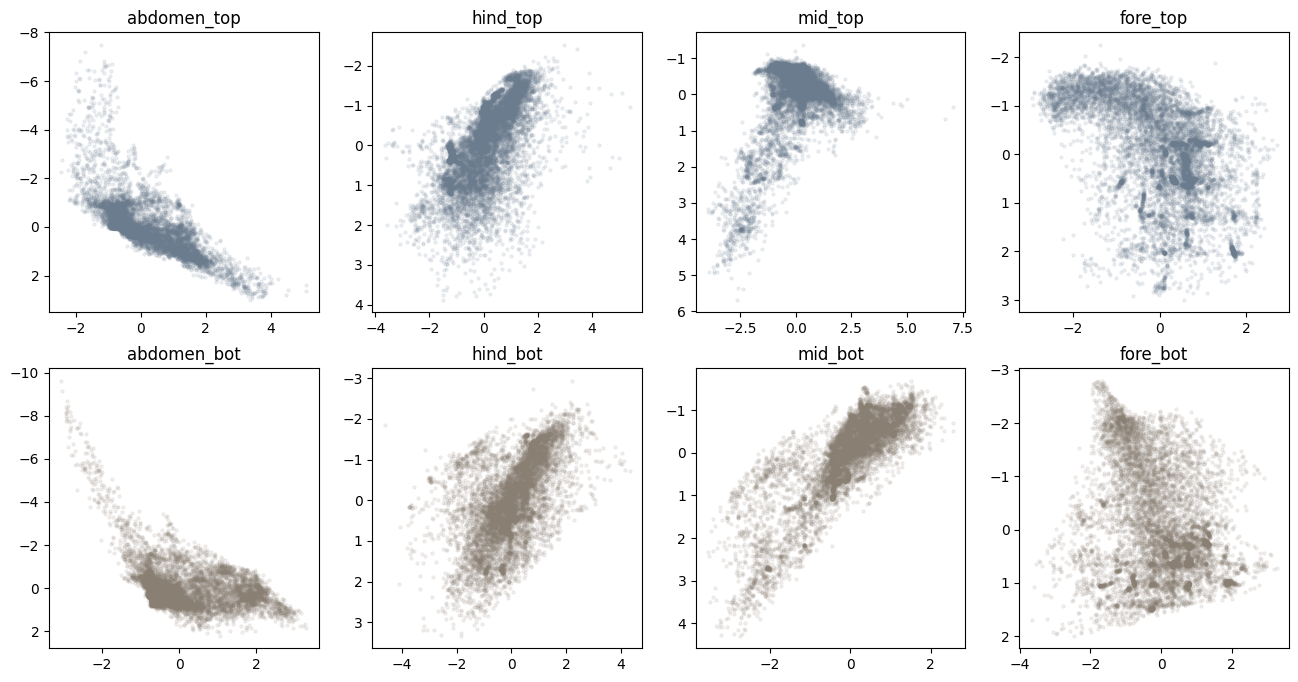

In [9]:
plot_utils.plot_markers(markers_zs[plot_idx], join_topbot=False)

# PCA raw

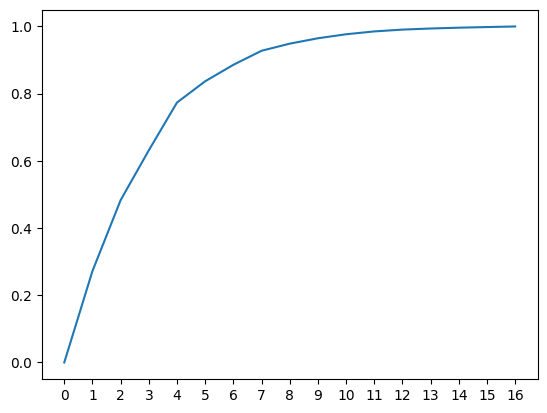

In [10]:
n_pc = 16
pca = PCA(n_components=n_pc)
markers_zs_reduced = pca.fit_transform(markers_zs[plot_idx].values)
markers_zs_reconstructed = pca.inverse_transform(markers_zs_reduced)
modes = pd.DataFrame(data=markers_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_zs_reconstructed, columns=markers[plot_idx].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
plt.xticks(range(16+1))
pass

In [11]:
n_pc = 2
pca = PCA(n_components=n_pc)
markers_zs_reduced = pca.fit_transform(markers_zs[plot_idx])
markers_zs_reconstructed = pca.inverse_transform(markers_zs_reduced)
modes = pd.DataFrame(data=markers_zs_reduced, columns=[f'PC{n + 1}' for n in range(n_pc)])
recon = pd.DataFrame(data=markers_zs_reconstructed, columns=markers[plot_idx].columns)
loadings = pca.components_
vars_expl = pca.explained_variance_ratio_

# plt.plot([np.sum(vars_expl[:idx]) for idx in range(vars_expl.shape[0]+1)])
# plt.xticks(range(n_pc+1))
print(np.sum(vars_expl[:vars_expl.shape[0]]))

0.4831766366211157


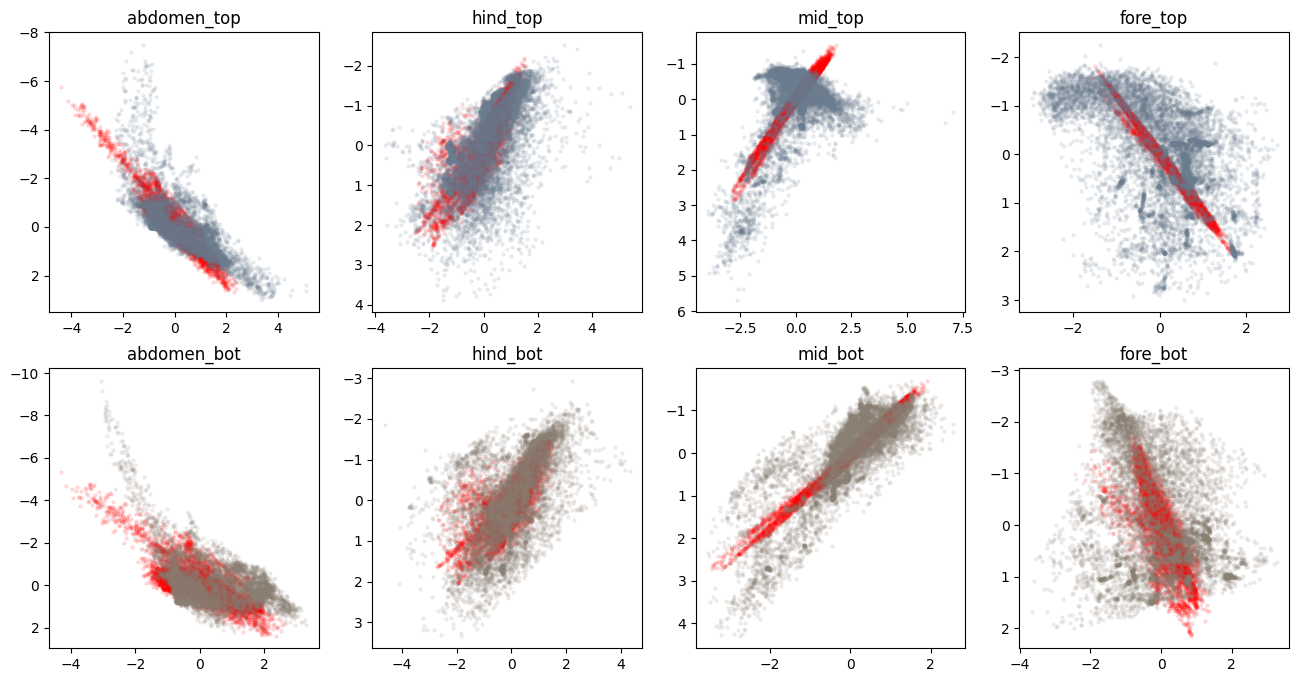

In [12]:
plot_utils.plot_markers(markers_zs[plot_idx], recon, join_topbot=False)

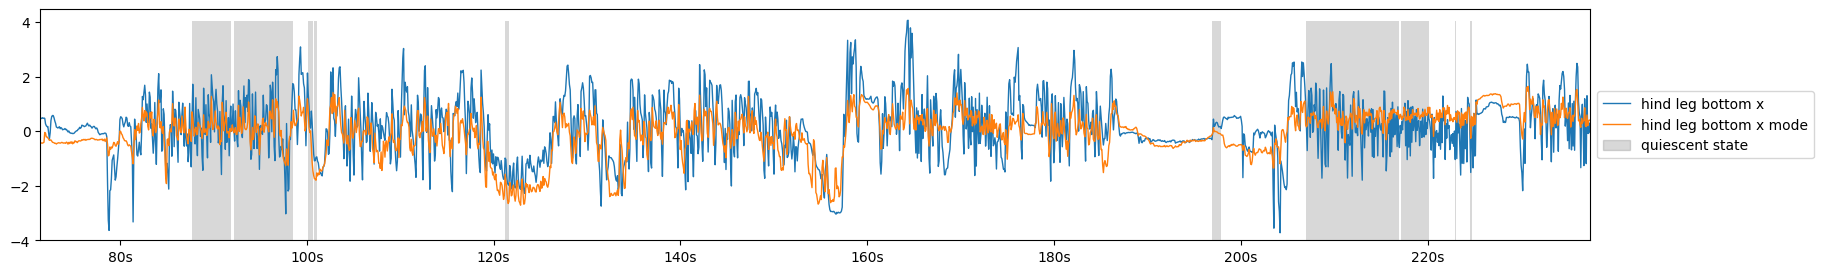

In [13]:
# Select the range you want to plot
min_x = 500
max_x = 2500

# Prepare the heatmap data (example: using 'still' state)
heatmap = states[plot_idx]['still'].values[min_x:max_x + 1].reshape(-1, 1)
heatmap = heatmap.T  # shape (1, timepoints)

# Prepare the timestamps for the selected range
timestamps_sel = timestamps[plot_idx][min_x:max_x + 1]

plt.figure(figsize=(20, 3))


# Plot the heatmap, aligned with timestamps
plt.imshow(
    heatmap,
    aspect='auto',
    cmap=mplcolors.LinearSegmentedColormap.from_list(
        'middle_third',
        plt.get_cmap('binary')(np.linspace(0, 1 / 2, 256))
    ),
    interpolation='nearest',
    alpha=0.3,
    extent=[timestamps_sel[0], timestamps_sel[-1], -4, 4],
)

lw = 1
# Plot your traces as before
# plt.plot(timestamps_sel, recon.loc[min_x:max_x, ['abdomen-bot_x']].values, label='abdomen bottom x', linewidth=lw)
plt.plot(timestamps_sel, markers_zs[plot_idx].loc[min_x:max_x, ['hind-bot_x']].values, label='hind leg bottom x', linewidth=lw)
plt.plot(timestamps_sel, recon.loc[min_x:max_x, ['hind-bot_x']].values, label='hind leg bottom x mode', linewidth=lw)
# plt.plot(timestamps_sel, recon.loc[min_x:max_x, ['mid-bot_x']].values, label='mid leg bottom', linewidth=lw)
# plt.plot(timestamps_sel, recon.loc[min_x:max_x, ['fore-bot_x']].values, label='front leg bottom x', linewidth=lw)
# plt.plot(timestamps_sel, traces.loc[min_x:max_x, ['00_000']] * 100, label='example neuron', linewidth=1.5, color='black')

plt.xticks(plt.xticks()[0], [f'{int(t)}s' for t in plt.xticks()[0]])
plt.xlim(timestamps_sel[0], timestamps_sel[-1])
heatmap_patch = patches.Patch(color='gray', alpha=0.3, label='quiescent state')
plt.legend(
    handles=plt.gca().get_legend_handles_labels()[0] + [heatmap_patch],
    loc='center left', bbox_to_anchor=(1, 0.5)
)
plt.savefig('../../out/plots/markers_traces', dpi=300, bbox_inches='tight')
plt.show()

# grad

In [14]:
markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]
markers_grad_zs = [
	pd.DataFrame(
		data=(marker_grad.values - marker_grad.values.mean(axis=0)) / np.where((marker_std := np.std(marker_grad.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker_grad.columns)
	for marker_grad in markers_grad
]

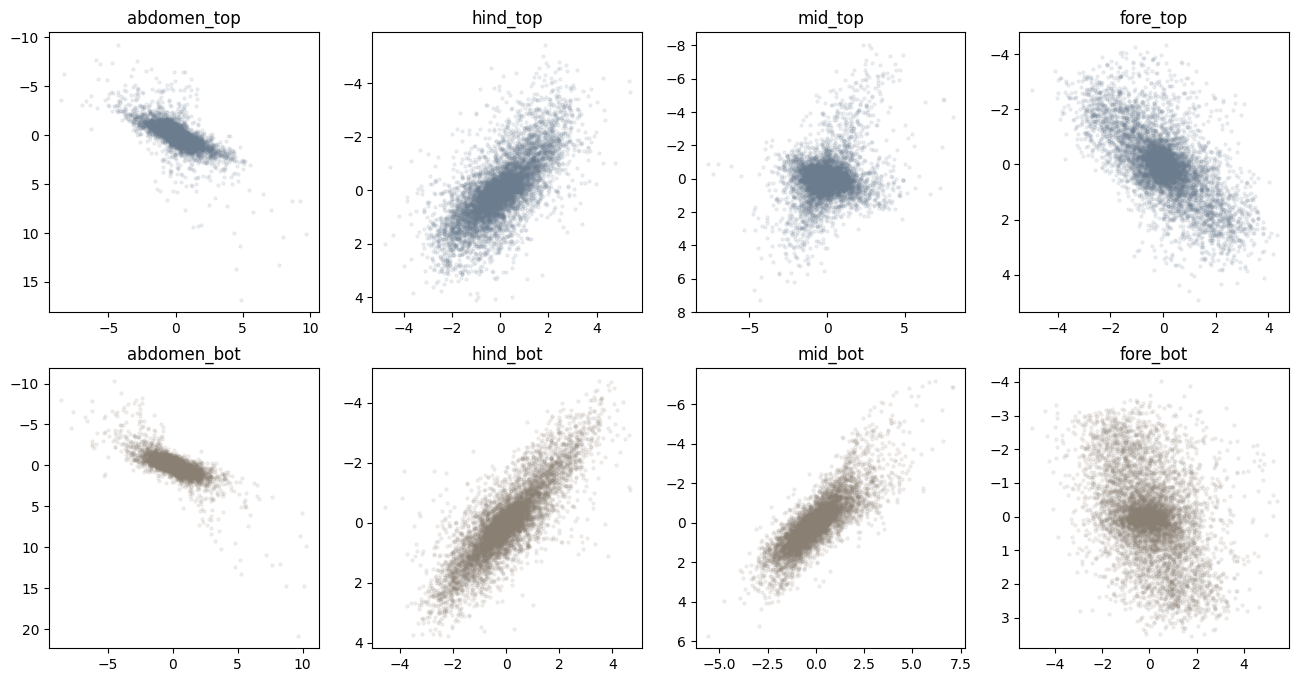

In [15]:
plot_utils.plot_markers(markers_grad_zs[plot_idx], join_topbot=False)

# ALIGNMENT ACROSS FLIES

In [16]:
from cycler import cycler

In [17]:
def plot_markers_stacked(markers_list, save_path=None):
	fig, axes = plt.subplots(2, 4, figsize=(16, 8), squeeze=False)

	plt.rcParams['axes.prop_cycle'] = cycler(color=plt.cm.tab20.colors)
	colors = iter(plt.rcParams['axes.prop_cycle'].by_key()['color'])

	for markers in markers_list:
		color = next(colors)

		for i in range(4):
			name = markers.columns[i * 4].split('-')[0]

			ax = axes[0, i]
			ax.scatter(markers[f'{name}-top_x'].values, markers[f'{name}-top_y'].values, color=color, alpha=0.05, s=5)

			ax.invert_yaxis()
			ax.set_title(name + '_top')
			ax = axes[1, i]
			ax.scatter(markers[f'{name}-bot_x'].values, markers[f'{name}-bot_y'].values, color=color, alpha=0.05, s=5)
			ax.invert_yaxis()
			ax.set_title(name + '_bot')

		if save_path is not None: plt.savefig(f'{save_path}.png', dpi=300, bbox_inches='tight')

	plt.show()

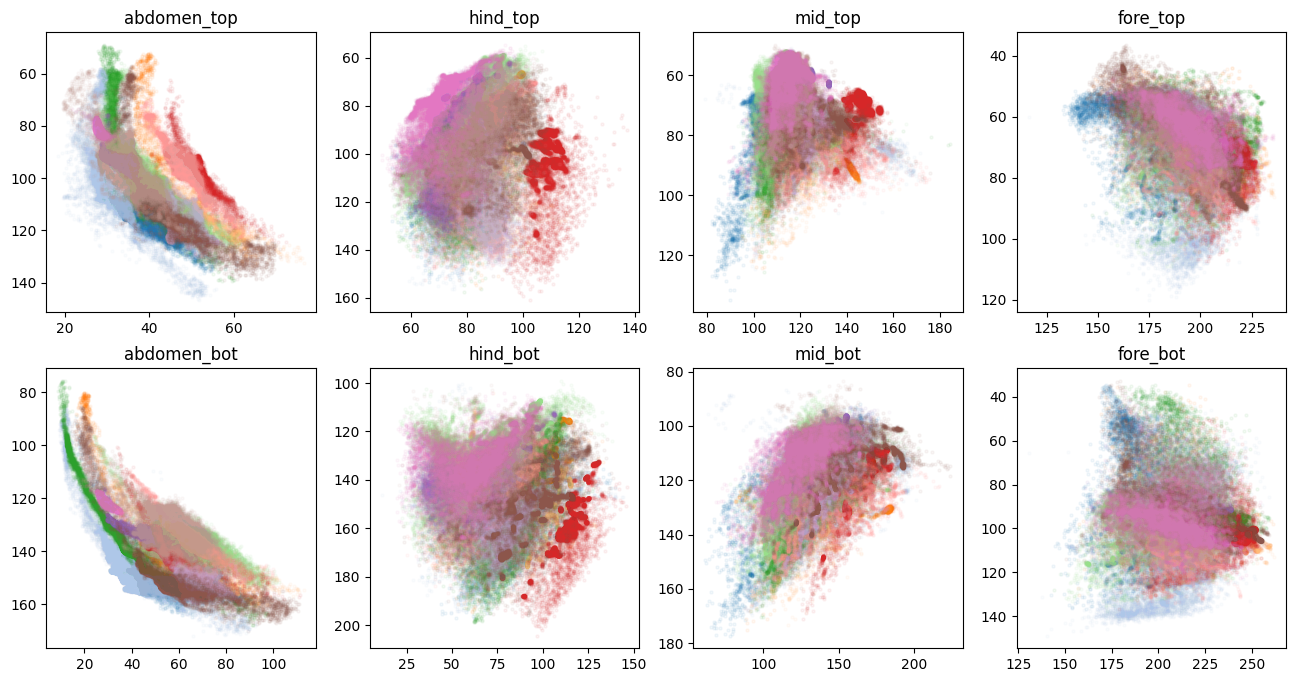

In [18]:
plot_markers_stacked(markers)

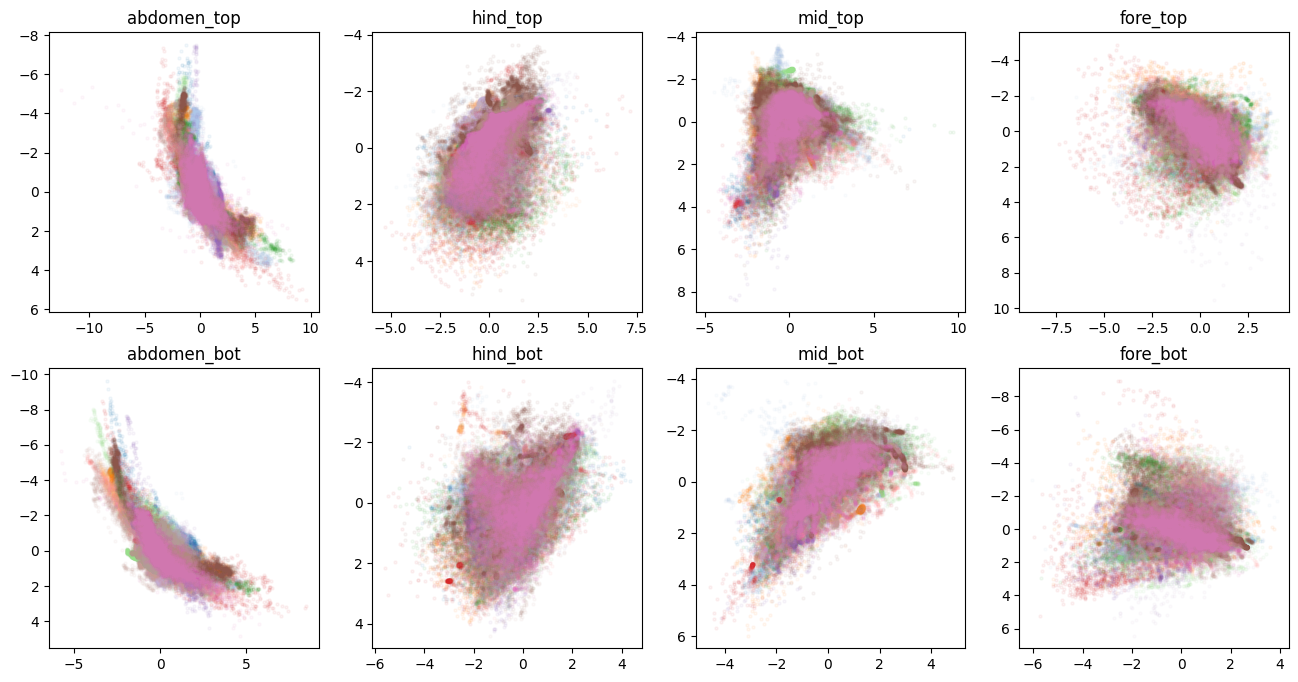

In [19]:
plot_markers_stacked(markers_zs)